# 02 - Feature Engineering, RFM Segmentation & Clustering

**Goal:** turn orders into one row per customer and group customers by behaviour.

Features are built **only from orders up to the cutoff date (2025-07-01)**. Churn is measured *after* the
cutoff, so the model never sees the future (no data leakage).

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.append("../src")          # lets us reuse helper functions from src/pipeline.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:
from pipeline import load_and_clean, build_features, rfm_segments, CUTOFF, HORIZON
orders = load_and_clean()
feat = build_features(orders)
print(f"Cutoff: {CUTOFF.date()} | churn = no purchase in the next {HORIZON} days")
print(f"Customers: {len(feat):,} | churn rate: {feat['churn'].mean():.1%}")
feat.head()

[clean] raw=28,325 | duplicates=266 | missing customer=283 | cancellations=420 | clean=27,356
Cutoff: 2025-07-01 | churn = no purchase in the next 120 days
Customers: 1,699 | churn rate: 50.6%


,first_order,last_order,frequency,monetary,n_categories,discount_rate,return_rate,avg_review,country,recency,tenure_days,aov,avg_gap_days,orders_last_90d,churn
customer_id,,,,,,,,,,,,,,,
1,2024-03-04,2025-05-25,49,"4,711.34",6,0.31,0.06,4.35,Germany,37,484,96.15,10.08,9.00,0
2,2024-07-11,2024-07-11,1,0.00,1,0.00,1.00,4.00,United Kingdom,355,355,0.00,365.00,0.00,1
4,2025-01-23,2025-06-15,7,507.24,4,0.71,0.00,3.86,USA,16,159,72.46,26.50,5.00,0
5,2024-01-06,2025-06-02,29,"2,461.39",6,0.24,0.07,4.45,Germany,29,542,84.88,19.36,2.00,0
6,2024-12-24,2025-04-01,11,891.80,4,0.64,0.09,2.36,USA,91,189,81.07,18.90,0.00,1


## 1. Customer-level features

In [3]:
feat[["recency", "frequency", "monetary", "aov", "tenure_days", "avg_gap_days", "orders_last_90d",
      "return_rate", "avg_review"]].describe().T

,count,mean,std,min,25%,50%,75%,max
recency,"1,699.00",118.15,140.21,0.00,12.00,44.00,202.00,543.00
frequency,"1,699.00",10.47,11.20,1.00,3.00,7.00,14.00,91.00
monetary,"1,699.00",852.73,"1,090.96",0.00,177.88,489.35,"1,087.99","8,936.81"
aov,"1,699.00",80.41,55.44,0.00,45.97,67.38,96.81,445.80
tenure_days,"1,699.00",277.61,158.86,0.00,139.00,279.00,415.00,547.00
avg_gap_days,"1,699.00",99.39,126.29,2.00,18.05,37.75,107.00,543.00
orders_last_90d,"1,699.00",2.63,3.35,0.00,0.00,1.00,4.00,19.00
return_rate,"1,699.00",0.08,0.16,0.00,0.00,0.00,0.09,1.00
avg_review,"1,699.00",3.86,0.75,1.00,3.50,4.06,4.33,5.00


## 2. RFM scoring
- **Recency** - days since last order (lower is better)
- **Frequency** - number of orders
- **Monetary** - total net spend

Each is scored 1-5 by quintile, then combined into named segments.

In [4]:
feat = rfm_segments(feat)
seg = feat.groupby("segment").agg(customers=("recency", "size"), avg_recency=("recency", "mean"),
                                   avg_orders=("frequency", "mean"), avg_spend=("monetary", "mean"),
                                   total_spend=("monetary", "sum"), churn_rate=("churn", "mean"))
seg["revenue_share"] = seg["total_spend"] / seg["total_spend"].sum()
seg.sort_values("total_spend", ascending=False)

,customers,avg_recency,avg_orders,avg_spend,total_spend,churn_rate,revenue_share
segment,,,,,,,
Champions,368,8.69,22.34,"1,798.07","661,687.95",0.10,0.46
At Risk,332,229.67,12.17,"1,013.58","336,507.52",0.94,0.23
Loyal Customers,319,33.68,12.01,976.83,"311,608.13",0.32,0.22
Lost / Hibernating,348,291.49,2.38,194.89,"67,823.46",0.94,0.05
New / Promising,191,10.90,2.60,224.05,"42,792.66",0.15,0.03
Needs Attention,141,49.74,2.62,201.25,"28,376.63",0.40,0.02


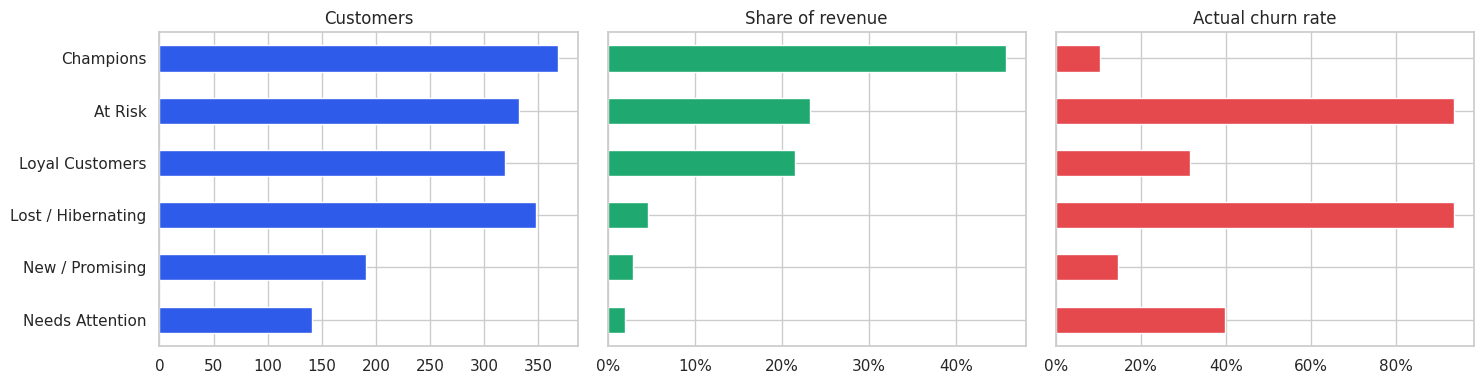

In [5]:
order = seg.sort_values("total_spend").index
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col, color, title in zip(ax, ["customers", "revenue_share", "churn_rate"],
                                ["#2F5BEA", "#1FA971", "#E5484D"],
                                ["Customers", "Share of revenue", "Actual churn rate"]):
    seg.loc[order, col].plot.barh(ax=a, color=color); a.set_title(title); a.set_ylabel("")
for a in ax[1:]:
    a.set_yticklabels([]); a.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
plt.tight_layout()

In [6]:
top20 = feat["monetary"].sort_values(ascending=False).head(int(len(feat) * 0.2)).sum() / feat["monetary"].sum()
print(f"Top 20% of customers generate {top20:.0%} of net revenue")

Top 20% of customers generate 59% of net revenue


## 3. K-Means clustering
RFM rules are easy to explain; clustering lets the data find its own groups. We log-transform and scale
recency, frequency and spend, then use the **elbow method** and **silhouette score** to sanity-check *k*.

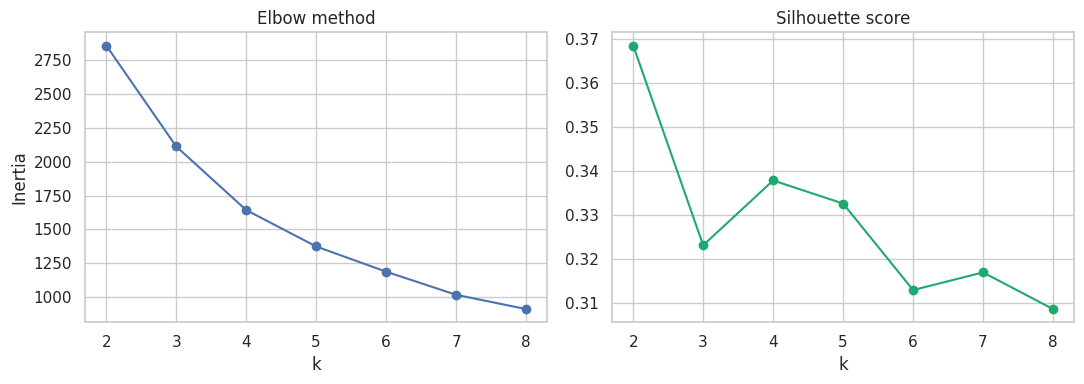

In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

X = StandardScaler().fit_transform(np.log1p(feat[["recency", "frequency", "monetary"]]))
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_, sample_size=1500, random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(list(ks), inertia, marker="o"); ax[0].set(title="Elbow method", xlabel="k", ylabel="Inertia")
ax[1].plot(list(ks), sil, marker="o", color="#1FA971"); ax[1].set(title="Silhouette score", xlabel="k")
plt.tight_layout()

In [8]:
K = 4   # chosen for business interpretability; silhouette/elbow shown above
feat["cluster"] = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(X)
feat.groupby("cluster").agg(customers=("recency", "size"), recency=("recency", "mean"),
                            frequency=("frequency", "mean"), spend=("monetary", "mean"),
                            churn_rate=("churn", "mean")).round(2)

,customers,recency,frequency,spend,churn_rate
cluster,,,,,
0,528,214.52,8.16,666.86,0.85
1,371,12.70,5.97,443.83,0.14
2,424,25.48,25.02,"2,120.50",0.22
3,376,191.35,1.73,87.61,0.70


### Key takeaways
- The top 20% of customers generate about 59% of net revenue, and **Champions** (22% of customers) generate 46%.
- **At Risk** customers are about 20% of customers and 23% of historical revenue, yet 94% of them have already churned.
- K-Means finds four groups: high-spend loyal buyers (22% churn), recent regulars (14%), past regulars who went quiet (85%) and low-value lapsed buyers (70%). They agree with the RFM story.

**Next:** `03_churn_modeling.ipynb`